<a href="https://colab.research.google.com/github/esratjahan57/tobacco_mosaicVirus/blob/main/TobaccoMosaicVirusE2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!unzip /content/drive/MyDrive/Tomato-Leaf-Disease-63.zip  -d /content/dataset


Streaming output truncated to the last 5000 lines.
  inflating: /content/dataset/Tomato-Leaf-Disease-63/labels/train/Early-Blight-881-_JPG.rf.ca81b7ee96622e4b3352accf8f4fe844.txt  
  inflating: /content/dataset/Tomato-Leaf-Disease-63/labels/train/Early-Blight-881-_JPG.rf.e26ae9de22db4a69d836092c14ef235f.txt  
  inflating: /content/dataset/Tomato-Leaf-Disease-63/labels/train/Early-Blight-888-_JPG.rf.0465068cd72cfa44889336bb801e38a8.txt  
  inflating: /content/dataset/Tomato-Leaf-Disease-63/labels/train/Early-Blight-888-_JPG.rf.38792c9f882a4552c736d23ba7cbc827.txt  
  inflating: /content/dataset/Tomato-Leaf-Disease-63/labels/train/Early-Blight-888-_JPG.rf.a3c887d5f5796cec8b7fd5cccedeb1c3.txt  
  inflating: /content/dataset/Tomato-Leaf-Disease-63/labels/train/Early-Blight-889-_JPG.rf.47780aa133182e4ca4c224f7352466fe.txt  
  inflating: /content/dataset/Tomato-Leaf-Disease-63/labels/train/Early-Blight-889-_JPG.rf.c6aefd8c973ea5016049a6cb5b52ddce.txt  
  inflating: /content/dataset/Tomato-Le

In [ ]:
# Create data.yaml
data_yaml = """
path: /content/dataset
train: /content/dataset/Tomato-Leaf-Disease-63/images/train
val: /content/dataset/Tomato-Leaf-Disease-63/images/val
test: /content/dataset/Tomato-Leaf-Disease-63/images/test

nc: 9  # change this to your actual number of classes
names: ['Early Blight', 'Healthy', 'Late Blight', 'Leaf Miner', 'Leaf Mold', 'Mosaic Virus', 'Septoria', 'Spider Mites', 'Yellow Leaf Curl Virus']
"""

with open('/content/dataset/data.yaml', 'w') as f:
    f.write(data_yaml)


In [ ]:
!pip install ultralytics --upgrade
from ultralytics import YOLO

# Optional: clear GPU memory
import torch
torch.cuda.empty_cache()

!yolo task=detect \
    mode=train \
    model=yolov8n.pt \
    data=/content/dataset/data.yaml \
    epochs=30 \
    imgsz=416 \
    batch=8 \
    workers=2 \
    name=tomato_leaf_yolov8_colab



Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
100% 6.25M/6.25M [00:00<00:00, 114MB/s]
Ultralytics 8.3.146 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, int8=F

In [ ]:
import os

# Search for any 'best.pt' file in the /content directory
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file == "best.pt":
            print("Found:", os.path.join(root, file))


Found: /content/runs/detect/tomato_leaf_yolov8_colab/weights/best.pt


In [ ]:
model_path = '/content/runs/detect/tomato_leaf_yolov8_colab/weights/best.pt'
model = YOLO(model_path)


In [ ]:
import os

# Search for all best.pt files under /content
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file == "best.pt":
            print("Found:", os.path.join(root, file))


Found: /content/runs/detect/tomato_leaf_yolov8_colab/weights/best.pt


In [ ]:
model_path = '/content/runs/detect/tomato_leaf_yolov8_colab/weights/best.pt'


In [ ]:
image_folder = '/content/tomato_dataset/test/images/'  # Update this if needed

In [ ]:
import os

# List top-level folders/files in /content/
print("Top-level contents in /content/:")
print(os.listdir('/content/'))

# If you see a dataset folder, list what's inside it
dataset_path = '/content/'  # adjust based on the output above

for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)
    if os.path.isdir(full_path):
        print(f"\nContents of folder: {full_path}")
        print(os.listdir(full_path))


Top-level contents in /content/:
['.config', 'runs', 'dataset', 'yolo11n.pt', 'yolov8n.pt', 'drive', 'sample_data']

Contents of folder: /content/.config
['.last_opt_in_prompt.yaml', 'gce', '.last_update_check.json', 'configurations', 'hidden_gcloud_config_universe_descriptor_data_cache_configs.db', 'config_sentinel', 'default_configs.db', 'logs', 'active_config', '.last_survey_prompt.yaml']

Contents of folder: /content/runs
['detect']

Contents of folder: /content/dataset
['data.yaml', 'Tomato-Leaf-Disease-63']

Contents of folder: /content/drive
['.file-revisions-by-id', 'MyDrive', '.shortcut-targets-by-id', '.Trash-0', '.Encrypted']

Contents of folder: /content/sample_data
['anscombe.json', 'README.md', 'california_housing_train.csv', 'mnist_train_small.csv', 'mnist_test.csv', 'california_housing_test.csv']


In [ ]:
from ultralytics import YOLO
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support
import torch
import os
import glob
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# ✅ SET your model path correctly
model_path = '/content/runs/detect/tomato_leaf_yolov8_colab2/weights/best.pt'  # change if needed
model = YOLO(model_path)

# ✅ Test data directory
test_dir = '/content/dataset/Tomato-Leaf-Disease-63/images/test'

# ✅ Class labels (must match your dataset)
class_names = ['Early Blight', 'Healthy', 'Late Blight', 'Leaf Miner', 'Leaf Mold',
               'Mosaic Virus', 'Septoria', 'Spider Mites', 'Yellow Leaf Curl Virus']

# ✅ Gather test images
image_paths = glob.glob(os.path.join(test_dir, '**/*.jpg'), recursive=True)

y_true, y_pred = [], []

# ✅ Run model on images
for img_path in image_paths:
    results = model(img_path)
    pred_cls = results[0].boxes.cls.cpu().numpy().astype(int) if results[0].boxes.cls.nelement() > 0 else []

    actual_cls_name = os.path.basename(os.path.dirname(img_path))
    if actual_cls_name not in class_names:
        continue
    actual_idx = class_names.index(actual_cls_name)
    y_true.append(actual_idx)

    pred_idx = int(pred_cls[0]) if len(pred_cls) > 0 else -1
    y_pred.append(pred_idx)

# ✅ Filter out -1 (no detection)
filtered_y_true = [yt for yp, yt in zip(y_pred, y_true) if yp != -1]
filtered_y_pred = [yp for yp in y_pred if yp != -1]

# ✅ Diagnostic info
print("🔍 Total test images:", len(image_paths))
print("✅ Predictions made:", len(filtered_y_pred))
print("❌ Skipped (no detection):", y_pred.count(-1))

# ✅ Check before computing metrics
if len(filtered_y_pred) == 0:
    print("\n⚠️ No valid predictions were made by the model.")
    print("Check if the model is trained correctly, or lower the confidence threshold.")
else:
    # ✅ Classification report
    print("\n📊 Classification Report:\n")
    print(classification_report(filtered_y_true, filtered_y_pred, target_names=class_names))

    # ✅ Accuracy
    acc = accuracy_score(filtered_y_true, filtered_y_pred)
    print("✅ Overall Accuracy:", round(acc, 4))

    # ✅ Class-wise metrics
    precision, recall, f1_score, _ = precision_recall_fscore_support(
        filtered_y_true, filtered_y_pred, labels=list(range(len(class_names)))
    )

    # ✅ Plot bar chart
    x = np.arange(len(class_names))
    width = 0.25
    plt.figure(figsize=(14, 6))
    plt.bar(x - width, precision, width, label='Precision')
    plt.bar(x, recall, width, label='Recall')
    plt.bar(x + width, f1_score, width, label='F1-Score')
    plt.ylabel('Score')
    plt.title('Performance per Class')
    plt.xticks(x, class_names, rotation=45, ha='right')
    plt.ylim(0, 1.1)
    plt.legend()
    plt.tight_layout()
    plt.grid(True)
    plt.show()



image 1/1 /content/dataset/Tomato-Leaf-Disease-63/images/test/collage_1270_jpg.rf.36c687909c89aefb3701677690bfd6f6.jpg: 416x416 2 Early Blights, 1 Leaf Mold, 1 Mosaic Virus, 8.7ms
Speed: 1.9ms preprocess, 8.7ms inference, 1.6ms postprocess per image at shape (1, 3, 416, 416)

image 1/1 /content/dataset/Tomato-Leaf-Disease-63/images/test/collage_1531_jpg.rf.37b15572a7750bdb6ae7804b3b26be1f.jpg: 416x416 1 Late Blight, 1 Leaf Mold, 1 Septoria, 1 Spider Mites, 6.4ms
Speed: 1.3ms preprocess, 6.4ms inference, 1.3ms postprocess per image at shape (1, 3, 416, 416)

image 1/1 /content/dataset/Tomato-Leaf-Disease-63/images/test/1c6727083428411181e9b58b4778c6b7_jpg.rf.6935942a2138dd0af594582199644691.jpg: 416x416 2 Leaf Miners, 6.4ms
Speed: 1.3ms preprocess, 6.4ms inference, 1.3ms postprocess per image at shape (1, 3, 416, 416)

image 1/1 /content/dataset/Tomato-Leaf-Disease-63/images/test/collage_391_jpg.rf.6a1fa81a7f4f190b10ddc63001d70b6d.jpg: 416x416 1 Early Blight, 1 Leaf Mold, 1 Mosaic Viru

In [ ]:
from ultralytics import YOLO

# Load the trained model
model = YOLO('/content/runs/detect/tomato_leaf_yolov8_colab2/weights/best.pt')  # path to best.pt

# Evaluate the model on the validation set
metrics = model.val(data='dataset/data.yaml', split='val')  # or use split='test' if you have a separate test set

# Print evaluation metrics
print("Validation Metrics:")
print(metrics)


Ultralytics 8.3.146 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,007,403 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1479.1±500.7 MB/s, size: 52.7 KB)


val: Scanning /content/dataset/Tomato-Leaf-Disease-63/labels/val.cache... 834 images, 0 backgrounds, 0 corrupt: 100%|██████████| 834/834 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 53/53 [00:08<00:00,  6.27it/s]


                   all        834       2653      0.925      0.917      0.969      0.897
          Early Blight        212        250      0.931      0.948      0.979      0.928
               Healthy         75        272      0.844      0.875      0.942      0.839
           Late Blight        232        324      0.974      0.963      0.991      0.935
            Leaf Miner        199        259      0.937      0.996      0.994      0.942
             Leaf Mold        211        338      0.909      0.905      0.968      0.894
          Mosaic Virus        250        319      0.964      0.931      0.974      0.921
              Septoria        203        324      0.927      0.904      0.972      0.911
          Spider Mites        123        252      0.944      0.935      0.978      0.901
Yellow Leaf Curl Virus        152        315      0.897      0.794      0.928      0.799
Speed: 0.4ms preprocess, 2.3ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to runs/detect

In [ ]:
from ultralytics import YOLO

# Load trained model
model = YOLO('/content/runs/detect/tomato_leaf_yolov8_colab2/weights/best.pt')

# Run evaluation
metrics = model.val(data='dataset/data.yaml', split='val')  # or use 'test' if you want


Ultralytics 8.3.146 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,007,403 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1474.1±783.3 MB/s, size: 48.4 KB)


val: Scanning /content/dataset/Tomato-Leaf-Disease-63/labels/val.cache... 834 images, 0 backgrounds, 0 corrupt: 100%|██████████| 834/834 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 53/53 [00:07<00:00,  7.41it/s]


                   all        834       2653      0.925      0.917      0.969      0.897
          Early Blight        212        250      0.931      0.948      0.979      0.928
               Healthy         75        272      0.844      0.875      0.942      0.839
           Late Blight        232        324      0.974      0.963      0.991      0.935
            Leaf Miner        199        259      0.937      0.996      0.994      0.942
             Leaf Mold        211        338      0.909      0.905      0.968      0.894
          Mosaic Virus        250        319      0.964      0.931      0.974      0.921
              Septoria        203        324      0.927      0.904      0.972      0.911
          Spider Mites        123        252      0.944      0.935      0.978      0.901
Yellow Leaf Curl Virus        152        315      0.897      0.794      0.928      0.799
Speed: 0.2ms preprocess, 2.0ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to runs/detect

In [ ]:
from ultralytics import YOLO
import numpy as np

# Load the trained model using the correct path
model = YOLO('/content/runs/detect/tomato_leaf_yolov8_colab2/weights/best.pt')

# Evaluate the model on the validation set
metrics = model.val(data='dataset/data.yaml', split='val')  # or use 'test' if you have one

# Extract average performance metrics
precision = np.mean(metrics.box.p)       # average precision across classes
recall = np.mean(metrics.box.r)          # average recall across classes
map50 = metrics.box.map50                # mean AP at IoU=0.5
map5095 = np.mean(metrics.box.map)       # mean AP across IoU 0.5:0.95

# Print results
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"mAP@0.5: {map50:.4f}")
print(f"mAP@0.5:0.95: {map5095:.4f}")


Ultralytics 8.3.146 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,007,403 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1847.0±587.4 MB/s, size: 56.4 KB)


val: Scanning /content/dataset/Tomato-Leaf-Disease-63/labels/val.cache... 834 images, 0 backgrounds, 0 corrupt: 100%|██████████| 834/834 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 53/53 [00:08<00:00,  6.20it/s]


                   all        834       2653      0.925      0.917      0.969      0.897
          Early Blight        212        250      0.931      0.948      0.979      0.928
               Healthy         75        272      0.844      0.875      0.942      0.839
           Late Blight        232        324      0.974      0.963      0.991      0.935
            Leaf Miner        199        259      0.937      0.996      0.994      0.942
             Leaf Mold        211        338      0.909      0.905      0.968      0.894
          Mosaic Virus        250        319      0.964      0.931      0.974      0.921
              Septoria        203        324      0.927      0.904      0.972      0.911
          Spider Mites        123        252      0.944      0.935      0.978      0.901
Yellow Leaf Curl Virus        152        315      0.897      0.794      0.928      0.799
Speed: 0.3ms preprocess, 2.4ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to runs/detect

Saving V006_77_1_18_11_03_13_3_8419w_20200930_172_jpg.rf.85e31b13d9b170da6339464928e9f460.jpg to V006_77_1_18_11_03_13_3_8419w_20200930_172_jpg.rf.85e31b13d9b170da6339464928e9f460.jpg
Result: ❌ Defected leaf detected!


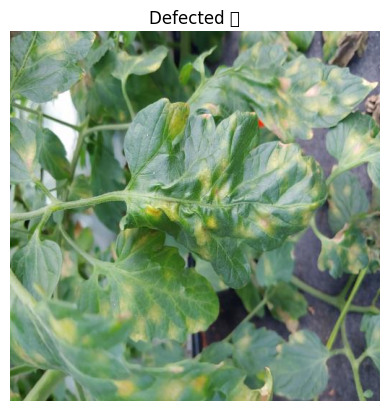

In [ ]:
from google.colab import files

uploaded = files.upload()  # This will let you upload an image from your local machine

# Get the uploaded image path
import os
image_path = list(uploaded.keys())[0]

# Now run detection
check_defect(image_path)


# New Section